# Analisis del dataset MNIST

## Objetivo 

Obtener el dataset y realizar el análisis para conocer las características del dataset antes de clasificarlo 

El análisis solicitado (EDA) consta de:
- Dimensiones 
- Clases 
- Estadísticas descriptivas  
- Ejemplos de los dígitos 
- Comparación entre clases 


In [3]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.5.4
Pandas: 3.0.6


## 1. obtencion del dataset 
MNIST es un conjunto de datos formado por imagenes de dígitos escritos a mano de 10 clases, con valores de 0 a 9.

Cada imagen es de 28x28 dando un total de 784 px, se obtendra el dataset mediante OpenML utilizando Scikit-learn


In [4]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml(
    "mnist_784",
    version=1,
    as_frame=False,
    parser="auto"
)

X = mnist.data #dartos de entrada (px)
y = mnist.target.astype(int) #etiquetas (No. img)

print("Dataset MNIST cargado correctamente")

Dataset MNIST cargado correctamente


In [5]:
print("Dimensiones de X", X.shape) #img x carct
print("Dimensiones de Y", y.shape) #imgs

print("\nNumero de imagenes:", X.shape[0])
print("Caracteristicas por imagen", X.shape[1])

Dimensiones de X (70000, 784)
Dimensiones de Y (70000,)

Numero de imagenes: 70000
Caracteristicas por imagen 784


## 2. Análisis EDA 

### Clases del dataset 

Identificacion de clases de MNIST así como la cantidad de imgs de cada dígito 

Clases encontradas: [0 1 2 3 4 5 6 7 8 9]
NUmero de clases: 10

Cantidad de imagenes por clase:
Digito0: 6903 imagenes
Digito1: 7877 imagenes
Digito2: 6990 imagenes
Digito3: 7141 imagenes
Digito4: 6824 imagenes
Digito5: 6313 imagenes
Digito6: 6876 imagenes
Digito7: 7293 imagenes
Digito8: 6825 imagenes
Digito9: 6958 imagenes


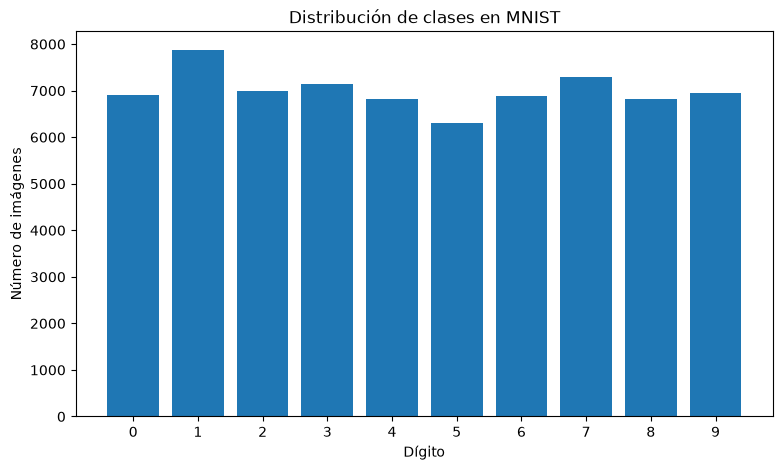

In [6]:
clases, cantidades = np.unique(y, return_counts=True) #valores en y y repeticion 

print("Clases encontradas:", clases)
print("NUmero de clases:", len(clases))

print("\nCantidad de imagenes por clase:")
for clase, cantidad in zip(clases, cantidades): #clase y cantidad 
    print(f"Digito{clase}: {cantidad} imagenes")


plt.figure(figsize=(9, 5))

plt.bar(clases, cantidades)

plt.title("Distribución de clases en MNIST")
plt.xlabel("Dígito")
plt.ylabel("Número de imágenes")
plt.xticks(clases)

plt.show()

### Interpretacion 

Como se puede observar nuestra dataset si contiene las 10 clases del 0 al 9.
Se puede observar que la cantidad de imagenes no es la misma, sin embargo no existe un abismo de diferencia por lo tanto no es muy grande el desbalance 

Los estadisticos se obtienen de la intensidad de pixeles para conocer la distribucion de los valores en las imagenes 

### Estadisticas descriptivas 

Se calculan estadísticas generales de las intensidades de los píxeles para
conocer el rango, tendencia central y dispersión de los datos.

Intensidad minima: 0
Intensidad maxima: 255
Promedio: 33.385964741253645
Mediana: 0.0
Desviacion estandar: 78.65437362689416
Suma de los valores faltantes:  0
Tipo de dato:  <class 'numpy.ndarray'>


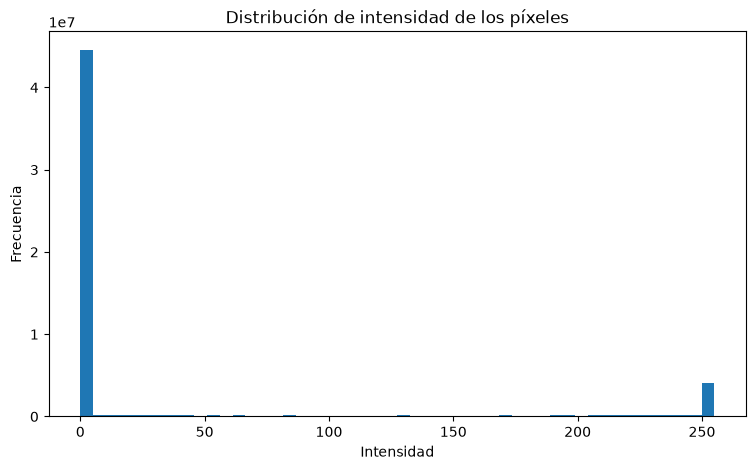

In [17]:
print("Intensidad minima:", np.min(X))
print("Intensidad maxima:", np.max(X))
print("Promedio:", np.mean(X))
print("Mediana:", np.median(X))
print("Desviacion estandar:", np.std(X))
print("Suma de los valores faltantes: ", np.isnan(X).sum())
print("Tipo de dato: ", type(X))

plt.figure(figsize=(9, 5))

plt.hist(X.ravel(), bins=50)

plt.title("Distribución de intensidad de los píxeles")
plt.xlabel("Intensidad")
plt.ylabel("Frecuencia")

plt.show()

### Interpretación 

Como sabemos las intensidades van de 0 a 255, podemos observar en la gráfica que la frecuencia que mas se repite es el 0, por lo tanto la mediana es 0 y promedio aproximado 33.39, esto hace sentido ya que gran parte de los pixeles representa el fondo 


### Visualización de ejemplos 

A continuación se muestran imagenes de ejemplo de las imagenes MNIST

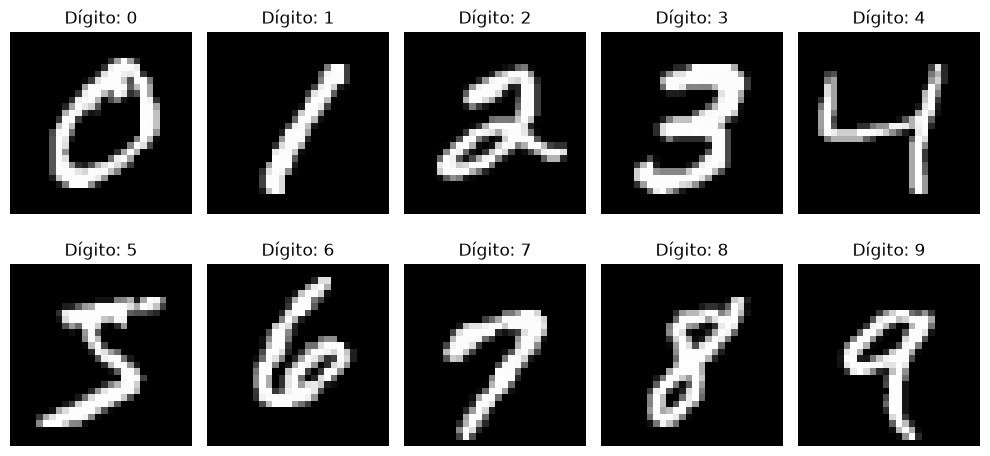

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5)) #fig en 10 para mostrar 10 img

for digito, ax in enumerate(axes.flat): #0 a 9
    indice = np.where(y == digito)[0][0] #dig en y y toma img 
    imagen = X[indice].reshape(28, 28) #toma img de 784 y la regresa a 28x28

    ax.imshow(imagen, cmap="gray") #Img a escala de grises 
    ax.set_title(f"Dígito: {digito}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Comparación entre clases

Se calcula la intensidad promedio y la desviación estándar de los píxeles
para cada clase con el objetivo de comparar las características generales
de los diferentes dígitos.

In [9]:
estadisticas_clases = []

for digito in clases:
    imagenes_clase = X[y == digito] #imgs que pertenecen a un digito

    promedio = np.mean(imagenes_clase)
    desviacion = np.std(imagenes_clase)

    estadisticas_clases.append([digito, promedio, desviacion]) #guardar y hacer tabla 

tabla_estadisticas = pd.DataFrame(
    estadisticas_clases,
    columns=["Dígito", "Promedio", "Desviación estándar"]
)

tabla_estadisticas


,Dígito,Promedio,Desviación estándar
0,0,44.177405,88.643286
1,1,19.406802,62.347559
2,2,38.034208,83.171552
3,3,36.154209,81.154922
4,4,30.996000,75.925956
5,5,32.950159,77.565749
6,6,35.234865,80.541918
7,7,29.217987,74.404598
8,8,38.397901,83.059082
9,9,31.359408,76.280703


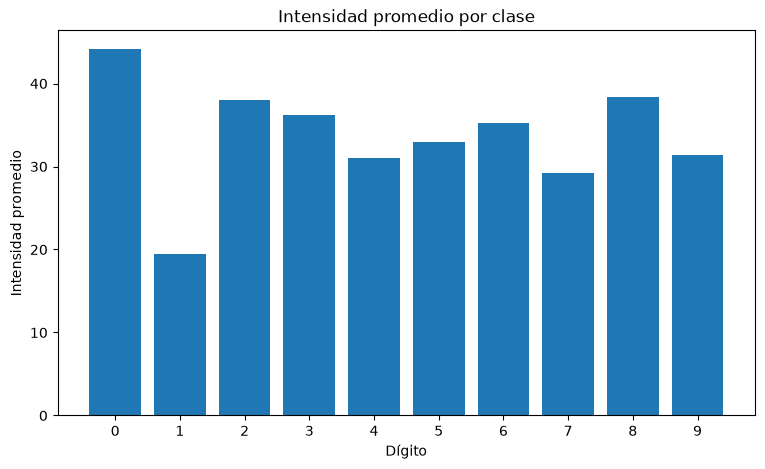

In [10]:
plt.figure(figsize=(9, 5))

plt.bar(
    tabla_estadisticas["Dígito"],
    tabla_estadisticas["Promedio"]
)

plt.title("Intensidad promedio por clase")
plt.xlabel("Dígito")
plt.ylabel("Intensidad promedio")
plt.xticks(clases)

plt.show()

### Interpretación

La intensidad promedio presenta diferencias entre las clases. El dígito 0
presenta el promedio más alto, con aproximadamente 44.18, mientras que el
dígito 1 presenta el menor, con aproximadamente 19.41.

Estas diferencias pueden estar relacionadas con la cantidad de píxeles que
ocupan los trazos de cada dígito. Sin embargo, los valores promedio no describen
por completo la forma de las imágenes y existe variabilidad dentro de cada clase.

### Imagen promedio por cada clase 
por cada clase se obtiene una img promedio para ver las regiones con con mayor frecuencia de intensidad de los pixeles

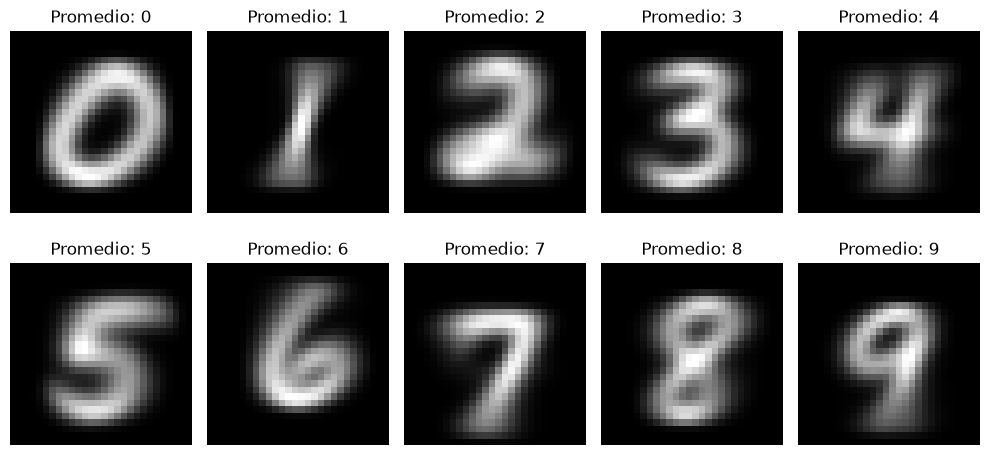

In [11]:
fig, axes = plt.subplots(2,5, figsize=(10,5))

for digito, ax in enumerate(axes.flat):
    imagenes_clase = X[y == digito]

    imagen_promedio = np.mean(imagenes_clase, axis=0) #promedio pixel por pixel 
    imagen_promedio = imagen_promedio.reshape(28, 28)


    ax.imshow(imagen_promedio, cmap="gray")
    ax.set_title(f"Promedio: {digito}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### 3.Preparacion de datos

Como sabemos el dataset debe dividirse en 2 partes, la parte de entrenamiento y la parte de prueba para preparar datos que serán utilizados por los algoritmos de clasificacion 

Se utilizara una division estratificada para tratar de conservar la misma proporcion en cada clase 

In [15]:
X_train, y_train = X[:60000], y[:60000]
X_test, y_test = X[60000:], y[60000:]

print("Entrenamiento:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nPrueba:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Entrenamiento:
X_train: (60000, 784)
y_train: (60000,)

Prueba:
X_test: (10000, 784)
y_test: (10000,)


In [14]:
clases_train, cantidades_train = np.unique(y_train, return_counts=True) #ej de cada dig 
clases_test, cantidades_test = np.unique(y_test, return_counts=True)

print("Clase | Train | Test")
print("--------------------")

for clase, train, test in zip(clases_train, cantidades_train, cantidades_test): #juntamos los 3 datos
    print(f"  {clase}   | {train:5d} | {test:4d}")

Clase | Train | Test
--------------------
  0   |  5522 | 1381
  1   |  6302 | 1575
  2   |  5592 | 1398
  3   |  5713 | 1428
  4   |  5459 | 1365
  5   |  5050 | 1263
  6   |  5501 | 1375
  7   |  5834 | 1459
  8   |  5460 | 1365
  9   |  5567 | 1391
